<a href="https://colab.research.google.com/github/Mkhalifa8996/Data-Science/blob/main/Transfer_Learning_ScalingUp/Transfer_Learning_ScalingUp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# New Section



In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import random, os, pathlib
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.image as mpimg
from sklearn.metrics import  accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report


# Creating helper functions
**It's a file of commonly used functions, that is saved to my gethub, It can be found here: https://raw.githubusercontent.com/Mkhalifa8996/Data-Science/refs/heads/main/extras/helper_functions.py**

In [ ]:
# Check if the GPU is  available
!nvidia-smi

Mon Oct 26 12:30:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Importing the helper functions from gethub
**A series of helper functions to do different tasks**

In [ ]:
!wget https://raw.githubusercontent.com/Mkhalifa8996/Data-Science/refs/heads/main/extras/helper_functions.py

--2026-10-26 12:30:53--  https://raw.githubusercontent.com/Mkhalifa8996/Data-Science/refs/heads/main/extras/helper_functions.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 11588 (11K) [text/plain]
Saving to: ‘helper_functions.py’

helper_functions.py 100%[===================>]  11.32K  --.-KB/s    in 0s      

2026-10-26 12:30:54 (105 MB/s) - ‘helper_functions.py’ saved [11588/11588]



In [ ]:
# Once we import the helper_functions file we import methds from it
from helper_functions import create_tensorboard_callback, plot_loss_curves, walk_through_dir, compare_historys, unzip_data

# We will work on 101 Food Classes
**First we will work on 10% of the dataset**

In [ ]:
# Import 10% of the dataset
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/101_food_classes_10_percent.zip

--2026-10-26 12:30:54--  https://storage.googleapis.com/ztm_tf_course/food_vision/101_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 104.154.124.27, 34.153.2.27, 34.3.1.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|104.154.124.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1625420029 (1.5G) [application/zip]
Saving to: ‘101_food_classes_10_percent.zip’

101_food_classes_10 100%[===================>]   1.51G  18.7MB/s    in 84s     

2026-10-26 12:32:18 (18.5 MB/s) - ‘101_food_classes_10_percent.zip’ saved [1625420029/1625420029]



In [ ]:
# Unzipping the data
unzip_data("/content/101_food_classes_10_percent.zip")

In [ ]:
walk_through_dir("/content/101_food_classes_10_percent")

There are 2 directories and 0 images in '/content/101_food_classes_10_percent'.
There are 101 directories and 0 images in '/content/101_food_classes_10_percent/train'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/chocolate_mousse'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/foie_gras'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/gyoza'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/risotto'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/spaghetti_bolognese'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/shrimp_and_grits'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/fried_calamari'.
There are 0 directories and 75 images in '/content/101_food_classes_10_percent/train/waffles'.
There are 0 directories and 75 imag

In [ ]:
# Set the training and test dirs
train_dir_10_percent = "/content/101_food_classes_10_percent/train"
test_dir = "/content/101_food_classes_10_percent/test"

In [ ]:
# Set Global variables
IMG_SIZE = (224,224)
BATCH_SIZE =32
INPUT_SIZE = IMG_SIZE +(3,)
EPOCHS = 5

In [ ]:
# Set the data inputs, create image datasets from train and test directories

train_data_10_percent = image_dataset_from_directory(
    directory=train_dir_10_percent,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_data = image_dataset_from_directory(
    directory=test_dir,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 7575 files belonging to 101 classes.
Found 25250 files belonging to 101 classes.


# The steps we are going to take:
1.   Create a ModelCheckpoint callback
2.   Create a data augmentation layer right into the model.
3.   Build a headless, functional EfficientNetB0 (we will create its output layer).
4.   Feature extraction.





**1. Creating a ModelCheckpoint callback**

In [ ]:
# Try to save model weights that result in maxuimum validation accuracy results
def create_checkpoint(checkpoint_path):
  checkpoint = tf.keras.callbacks.ModelCheckpoint(
      filepath = checkpoint_path, # Path to save checkpoint
      monitor = "val_accuracy", # the quantity to monitor
      mode = "max", # Save model/ weights only when model have maximum validation accuracy values
      save_weights_only = True, # Save only model weights, faster
      save_best_only = True,
      verbose = 1)
  return checkpoint


In [ ]:
# set the checkpoint path and create a Modelcheckpoint callback to store model weights
checkpoint_path = "101_classes_10_percent_checkpoint.weights.h5"

In [ ]:
# Create a data augmentation layer
data_augmentation = tf.keras.Sequential([
    # tf.keras.layers.Rescaling(1/255.0), # We don't use because EfficientNetB0 include rescaling layer
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomHeight(0.2),
    layers.RandomWidth(0.2),
    layers.RandomZoom(0.2),
])

# Creating a feature extraction model
**Effiecient model is trained on ImegeNet dataset with 1000 classes/outputs, but we will use feature extraction,  using only 101 classes/outputs**

In [ ]:
# Set up the base model and freeze it is layers
base_model = tf.keras.applications.EfficientNetB0(include_top=False)
base_model.trainable = False

# Set up the input layer
inputs = layers.Input(shape=INPUT_SIZE, name="input_layer")
"""
Pass our inputs through data augmentation layer,
so that augmentation happens during the training phase
"""
x = data_augmentation(inputs)

"""
# Pass the augmented data to the base model,
put base model in the inerence mode with training=False (weights are frozen)
"""
x = base_model(x, training=False)


# Dense the large feature tensor from the base_model into a feature vector
x = layers.GlobalAveragePooling2D(name="global_avg_pooling_layer")(x)

# The out but layer with 101 classes instead of 1000 classes
outputs = layers.Dense(len(train_data_10_percent.class_names), activation="softmax", name="output_layer")(x)

# Creating Feature Extractor Model
model_1 = tf.keras.Model(inputs, outputs)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
# Model_1 summary
model_1.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, None, None,     │     4,049,571 │
│                                 │ 1280)                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pooling_layer        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,178,952 (15.94 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Pass through model_1 layers, check trainable leyers
for layer_number, layer in enumerate(model_1.layers):
  print(layer_number, layer.name, layer.trainable)

0 input_layer True
1 sequential True
2 efficientnetb0 False
3 global_avg_pooling_layer True
4 output_layer True


In [ ]:
# Pass through base_model layers, check trainable leyers
for layer_number, layer in enumerate(model_1.layers[2].layers):
  print(layer_number, layer.name, layer.trainable)

0 input_layer False
1 rescaling False
2 normalization False
3 rescaling_1 False
4 stem_conv_pad False
5 stem_conv False
6 stem_bn False
7 stem_activation False
8 block1a_dwconv False
9 block1a_bn False
10 block1a_activation False
11 block1a_se_squeeze False
12 block1a_se_reshape False
13 block1a_se_reduce False
14 block1a_se_expand False
15 block1a_se_excite False
16 block1a_project_conv False
17 block1a_project_bn False
18 block2a_expand_conv False
19 block2a_expand_bn False
20 block2a_expand_activation False
21 block2a_dwconv_pad False
22 block2a_dwconv False
23 block2a_bn False
24 block2a_activation False
25 block2a_se_squeeze False
26 block2a_se_reshape False
27 block2a_se_reduce False
28 block2a_se_expand False
29 block2a_se_excite False
30 block2a_project_conv False
31 block2a_project_bn False
32 block2b_expand_conv False
33 block2b_expand_bn False
34 block2b_expand_activation False
35 block2b_dwconv False
36 block2b_bn False
37 block2b_activation False
38 block2b_se_squeeze Fals

# Compile model_1

In [ ]:
model_1.compile(
    loss="categorical_crossentropy",
    optimizer=Adam(),
    metrics=["accuracy"]
)

# Fit model_1


In [ ]:
history_101_classes_10_percent = model_1.fit(
    train_data_10_percent,
    epochs=EPOCHS,
    steps_per_epoch=len(train_data_10_percent),
    validation_data=test_data,
    validation_steps=int(0.15 * len(test_data)), # validate with only 15% of validation data
    callbacks=[create_checkpoint(checkpoint_path=checkpoint_path)]
)

Epoch 1/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.1690 - loss: 3.9496
Epoch 1: val_accuracy improved from None to 0.45630, saving model to 101_classes_10_percent_checkpoint.weights.h5

Epoch 1: finished saving model to 101_classes_10_percent_checkpoint.weights.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 49s 145ms/step - accuracy: 0.2752 - loss: 3.4053 - val_accuracy: 0.4563 - val_loss: 2.5219
Epoch 2/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.4872 - loss: 2.3157
Epoch 2: val_accuracy improved from 0.45630 to 0.53363, saving model to 101_classes_10_percent_checkpoint.weights.h5

Epoch 2: finished saving model to 101_classes_10_percent_checkpoint.weights.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 34s 135ms/step - accuracy: 0.4844 - loss: 2.2624 - val_accuracy: 0.5336 - val_loss: 2.0033
Epoch 3/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5542 - loss: 1.9014
Epoch 3: val_accuracy improved from 0.53363 to 0.54926, saving model to 101_classes_10_percent_checkpoint.weigh

In [ ]:
# Evaluating our model on the whole data
results_101_classes_10_percent = model_1.evaluate(test_data)
results_101_classes_10_percent

790/790 ━━━━━━━━━━━━━━━━━━━━ 60s 76ms/step - accuracy: 0.5801 - loss: 1.5861


[1.5860625505447388, 0.5801188349723816]

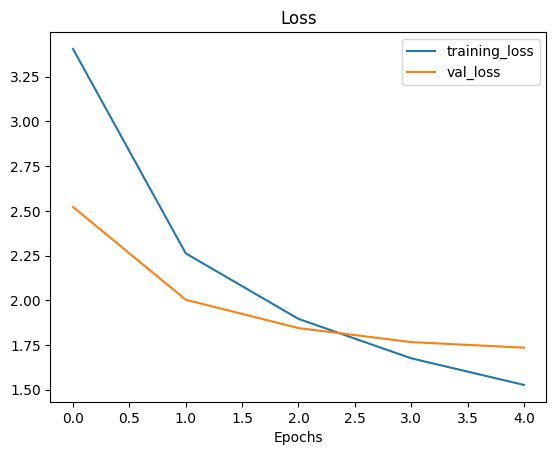

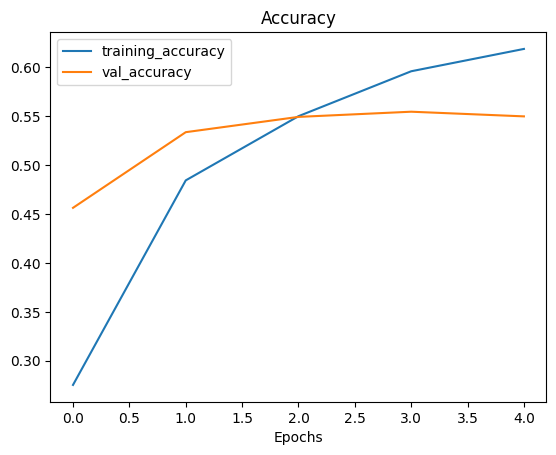

In [ ]:
# Plotting the loss and accuracy curves
plot_loss_curves(history_101_classes_10_percent)

**the accuracy and loss curves suggests that our model is overfitting (Performing too well on the training data but not generalizing ot unseen data)**

# EfficientNetB0 fine-tuning
**Usually bottom layers learn large features while top layers learn fine details, so We will unfreeze top layers**

In [ ]:
# Unfreeze the top 5 layers
for layer in base_model.layers[-5:]:
  layer.trainable = True

In [ ]:
# Recompile the model with lower learning rate
model_1.compile(
    loss="categorical_crossentropy",
    optimizer=Adam(learning_rate=0.0001),
    metrics=["accuracy"],
)

In [ ]:
# check trainable layers in model_1
for layer_number, layer in enumerate(model_1.layers[2].layers):
  print(layer_number, layer.name, layer.trainable)

0 input_layer False
1 rescaling False
2 normalization False
3 rescaling_1 False
4 stem_conv_pad False
5 stem_conv False
6 stem_bn False
7 stem_activation False
8 block1a_dwconv False
9 block1a_bn False
10 block1a_activation False
11 block1a_se_squeeze False
12 block1a_se_reshape False
13 block1a_se_reduce False
14 block1a_se_expand False
15 block1a_se_excite False
16 block1a_project_conv False
17 block1a_project_bn False
18 block2a_expand_conv False
19 block2a_expand_bn False
20 block2a_expand_activation False
21 block2a_dwconv_pad False
22 block2a_dwconv False
23 block2a_bn False
24 block2a_activation False
25 block2a_se_squeeze False
26 block2a_se_reshape False
27 block2a_se_reduce False
28 block2a_se_expand False
29 block2a_se_excite False
30 block2a_project_conv False
31 block2a_project_bn False
32 block2b_expand_conv False
33 block2b_expand_bn False
34 block2b_expand_activation False
35 block2b_dwconv False
36 block2b_bn False
37 block2b_activation False
38 block2b_se_squeeze Fals

In [ ]:
# Fine tune for 5 more epochs
fine_tune_epochs = EPOCHS + 5

# Fine-tune model_1
history_101_classes_10_percent_fine_tune = model_1.fit(
    train_data_10_percent,
    epochs=fine_tune_epochs,
    steps_per_epoch = len(train_data_10_percent),
    validation_data= test_data,
    validation_steps=int(0.15 * len(test_data)),
    initial_epoch = history_101_classes_10_percent.epoch[-1],
    verbose=1)

Epoch 5/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 46s 147ms/step - accuracy: 0.6445 - loss: 1.4666 - val_accuracy: 0.5625 - val_loss: 1.6979
Epoch 6/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 32s 136ms/step - accuracy: 0.6709 - loss: 1.3207 - val_accuracy: 0.5654 - val_loss: 1.6732
Epoch 7/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 41s 136ms/step - accuracy: 0.6911 - loss: 1.2426 - val_accuracy: 0.5718 - val_loss: 1.6384
Epoch 8/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 41s 136ms/step - accuracy: 0.7143 - loss: 1.1654 - val_accuracy: 0.5752 - val_loss: 1.6211
Epoch 9/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 41s 135ms/step - accuracy: 0.7324 - loss: 1.0941 - val_accuracy: 0.5792 - val_loss: 1.5979
Epoch 10/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 41s 172ms/step - accuracy: 0.7409 - loss: 1.0448 - val_accuracy: 0.5840 - val_loss: 1.5816


In [ ]:
#  Evaluating model on the full test data
results_101_classes_10_percent_fine_tune = model_1.evaluate(test_data)
results_101_classes_10_percent_fine_tune

790/790 ━━━━━━━━━━━━━━━━━━━━ 59s 75ms/step - accuracy: 0.6204 - loss: 1.4176


[1.4176315069198608, 0.6203564405441284]

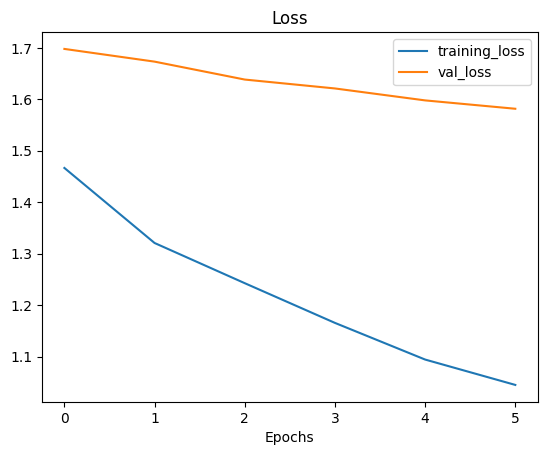

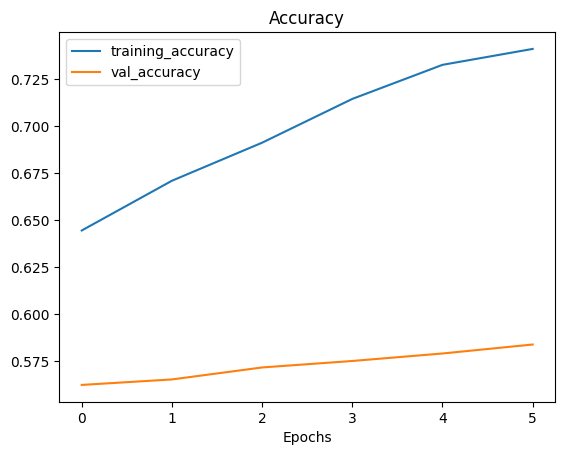

In [ ]:
# Plot the loss and accuracy curves
plot_loss_curves(history_101_classes_10_percent_fine_tune)

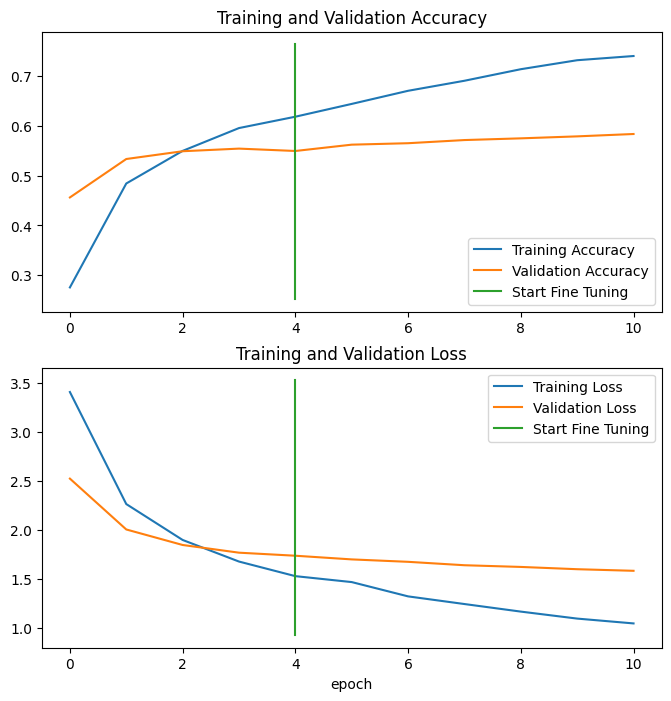

In [ ]:
# Comparing feature extraction and fine tuning results
compare_historys(history_101_classes_10_percent, history_101_classes_10_percent_fine_tune)

# Saving and loading a model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model_1_path = "/content/drive/MyDrive/DataScience/101_classes_10_percent_model.keras"
model_1.save(model_1_path)

# Load and evaluate our model

In [ ]:
model_1_loaded = tf.keras.models.load_model(model_1_path)

In [ ]:
model_1_loaded_results = model_1_loaded.evaluate(test_data)
model_1_loaded_results

790/790 ━━━━━━━━━━━━━━━━━━━━ 64s 76ms/step - accuracy: 0.6204 - loss: 1.4176


[1.4176315069198608, 0.6203564405441284]

In [ ]:
results_101_classes_10_percent_fine_tune == model_1_loaded_results

True

In [ ]:
preds_probs = model_1_loaded.predict(test_data, verbose=1)

790/790 ━━━━━━━━━━━━━━━━━━━━ 67s 83ms/step


In [ ]:
preds_probs

array([[4.1149318e-01, 7.8474794e-04, 1.9163702e-01, ..., 1.3518461e-04,
        5.5378610e-03, 1.4512887e-02],
       [9.4726861e-01, 2.5363602e-07, 1.3025415e-03, ..., 3.5863337e-03,
        7.5835112e-07, 1.4992681e-05],
       [5.1176882e-01, 6.6041048e-03, 3.0170800e-02, ..., 1.6785285e-03,
        3.3900916e-04, 1.3853679e-03],
       ...,
       [1.7477690e-04, 2.4635287e-01, 8.6797163e-06, ..., 1.9646743e-03,
        1.2221157e-03, 2.3207451e-01],
       [6.9386535e-03, 1.1975913e-02, 1.1422398e-02, ..., 1.6776384e-03,
        3.5419661e-04, 1.5806268e-01],
       [5.2155752e-02, 1.6499966e-03, 1.5672281e-02, ..., 3.2238488e-03,
        9.0737833e-04, 6.1950845e-01]], dtype=float32)

In [ ]:
preds_probs.shape

(25250, 101)

In [ ]:
print(f"Number of prediction probabilities for sample 5: {len(preds_probs[5])}")
print(f"The class with the highest predicted probability by the model for sample 5: {preds_probs[5].argmax()}")


Number of prediction probabilities for sample 5: 101
The class with the highest predicted probability by the model for sample 5: 78


**Preds_probs is a prediction array of our model's predictions, to evaluate them we need to compare them to their labels**

In [ ]:
# Get all test_data classes
class_names = os.listdir(test_dir)
len(class_names)

101

In [ ]:
test_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.float32, name=None))>

In [ ]:
# to get our test labels we need to unravel our test_data BatchDataset
y_labels= []
for images, labels in test_data.unbatch():
  y_labels.append(labels.numpy().argmax())

In [ ]:
print(y_labels[3000:3010])


[np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12)]


In [ ]:
# Get the classes of predicted probabilities
pred_classes = preds_probs.argmax(axis=1)
pred_classes[:10]

array([ 0,  0,  0, 38,  8, 78, 29,  0,  2,  0])

In [ ]:
# There is a vector of 101 values for each image
# Each value specify the prediction probability for each data class
preds_probs.argmax(axis=1).shape

(25250,)

In [ ]:
y_labels[:10]== preds_probs[:10].argmax(axis=1)

array([ True,  True,  True, False, False, False, False,  True, False,
        True])

# Evaluating model predictions
**We can use sklearn.metrics.accuracy_score**

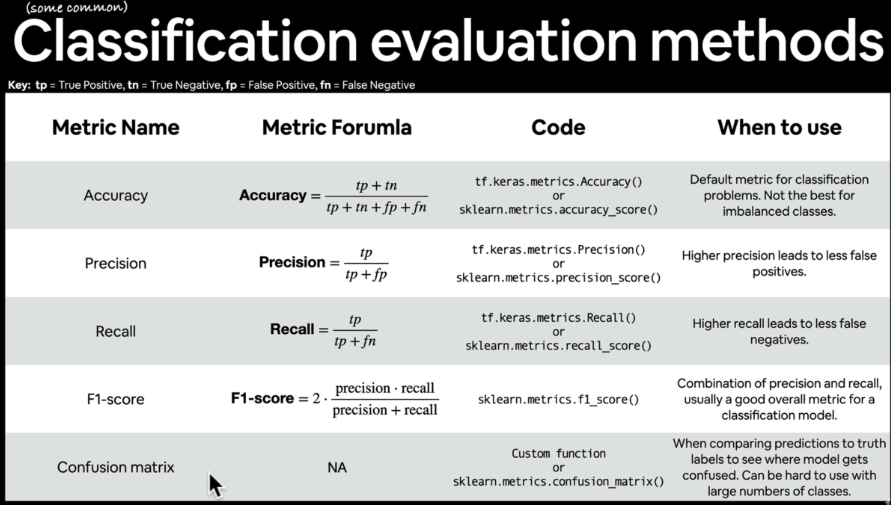

In [ ]:
sklearn_accuracy = accuracy_score(y_true= y_labels, y_pred= pred_classes)
sklearn_accuracy

0.6203564356435644

In [ ]:
cm = confusion_matrix(y_true= y_labels, y_pred= pred_classes)
cm

array([[ 61,   1,  23, ...,   7,   1,   8],
       [  0, 184,   0, ...,   0,   1,   0],
       [ 11,   2, 171, ...,   2,   1,   1],
       ...,
       [  2,   0,   1, ..., 134,   0,   0],
       [  2,   1,   0, ...,   1, 109,   0],
       [  2,   1,   1, ...,   6,   1, 169]])

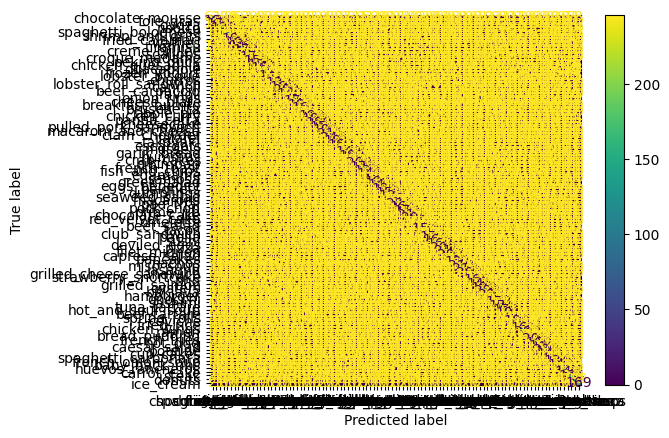

In [ ]:
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()

# Classiification reports
**A helpful function for acuiring many different classification metrics per class**

In [ ]:
# Printing the classification report
print(classification_report(y_true=y_labels, y_pred=pred_classes))

              precision    recall  f1-score   support

           0       0.28      0.24      0.26       250
           1       0.53      0.74      0.61       250
           2       0.57      0.68      0.62       250
           3       0.84      0.51      0.64       250
           4       0.68      0.42      0.52       250
           5       0.49      0.44      0.46       250
           6       0.76      0.79      0.77       250
           7       0.83      0.78      0.80       250
           8       0.27      0.57      0.36       250
           9       0.44      0.69      0.53       250
          10       0.58      0.41      0.48       250
          11       0.70      0.69      0.69       250
          12       0.74      0.61      0.67       250
          13       0.57      0.55      0.56       250
          14       0.52      0.66      0.58       250
          15       0.44      0.44      0.44       250
          16       0.68      0.58      0.62       250
          17       0.42    

In [ ]:
# Get a dictionary of the classification report
classification_report_dict = classification_report(y_true=y_labels, y_pred=pred_classes, output_dict=True)
classification_report_dict

{'0': {'precision': 0.2824074074074074,
  'recall': 0.244,
  'f1-score': 0.26180257510729615,
  'support': 250.0},
 '1': {'precision': 0.5257142857142857,
  'recall': 0.736,
  'f1-score': 0.6133333333333333,
  'support': 250.0},
 '2': {'precision': 0.5738255033557047,
  'recall': 0.684,
  'f1-score': 0.6240875912408759,
  'support': 250.0},
 '3': {'precision': 0.8366013071895425,
  'recall': 0.512,
  'f1-score': 0.6352357320099256,
  'support': 250.0},
 '4': {'precision': 0.6774193548387096,
  'recall': 0.42,
  'f1-score': 0.5185185185185185,
  'support': 250.0},
 '5': {'precision': 0.48672566371681414,
  'recall': 0.44,
  'f1-score': 0.46218487394957986,
  'support': 250.0},
 '6': {'precision': 0.7586206896551724,
  'recall': 0.792,
  'f1-score': 0.7749510763209393,
  'support': 250.0},
 '7': {'precision': 0.825531914893617,
  'recall': 0.776,
  'f1-score': 0.8,
  'support': 250.0},
 '8': {'precision': 0.26779026217228463,
  'recall': 0.572,
  'f1-score': 0.3647959183673469,
  'suppor

# Plotting F1-scores

In [ ]:
# Create empty dictionary to hold F1-scores
classes_f1_scores = {}
# Loop throug classification report dictionary
for k, v in classification_report_dict.items():
  if k== "accuracy":
    break
  else:
    classes_f1_scores[class_names[int(k)]]=v['f1-score']
classes_f1_scores

{'chocolate_mousse': 0.26180257510729615,
 'foie_gras': 0.6133333333333333,
 'gyoza': 0.6240875912408759,
 'risotto': 0.6352357320099256,
 'spaghetti_bolognese': 0.5185185185185185,
 'shrimp_and_grits': 0.46218487394957986,
 'fried_calamari': 0.7749510763209393,
 'waffles': 0.8,
 'tiramisu': 0.3647959183673469,
 'creme_brulee': 0.5349922239502333,
 'scallops': 0.4801864801864802,
 'croque_madame': 0.694949494949495,
 'peking_duck': 0.6681318681318681,
 'chicken_quesadilla': 0.563265306122449,
 'guacamole': 0.5774647887323944,
 'frozen_yogurt': 0.4386317907444668,
 'lobster_bisque': 0.625,
 'churros': 0.44652908067542213,
 'lobster_roll_sandwich': 0.5236220472440944,
 'cannoli': 0.6521739130434783,
 'beef_carpaccio': 0.7220216606498195,
 'ravioli': 0.570264765784114,
 'onion_rings': 0.381139489194499,
 'cheese_plate': 0.7450980392156863,
 'breakfast_burrito': 0.7464503042596349,
 'bruschetta': 0.7008547008547008,
 'apple_pie': 0.3801980198019802,
 'chicken_curry': 0.7524366471734892,
 '

In [ ]:
# Converting F-1 socres into dataframe
data = {"Class-names": classes_f1_scores.keys(),
        "f1_scores":classes_f1_scores.values()}
f1_scores = pd.DataFrame(data).sort_values("f1_scores", ascending=False)
f1_scores

,Class-names,f1_scores
33,falafel,0.966601
63,pizza,0.895075
75,baklava,0.854369
69,lasagna,0.846307
86,ramen,0.844898
...,...,...
50,macarons,0.363158
82,spring_rolls,0.344554
93,spaghetti_carbonara,0.338902
39,crab_cakes,0.336898


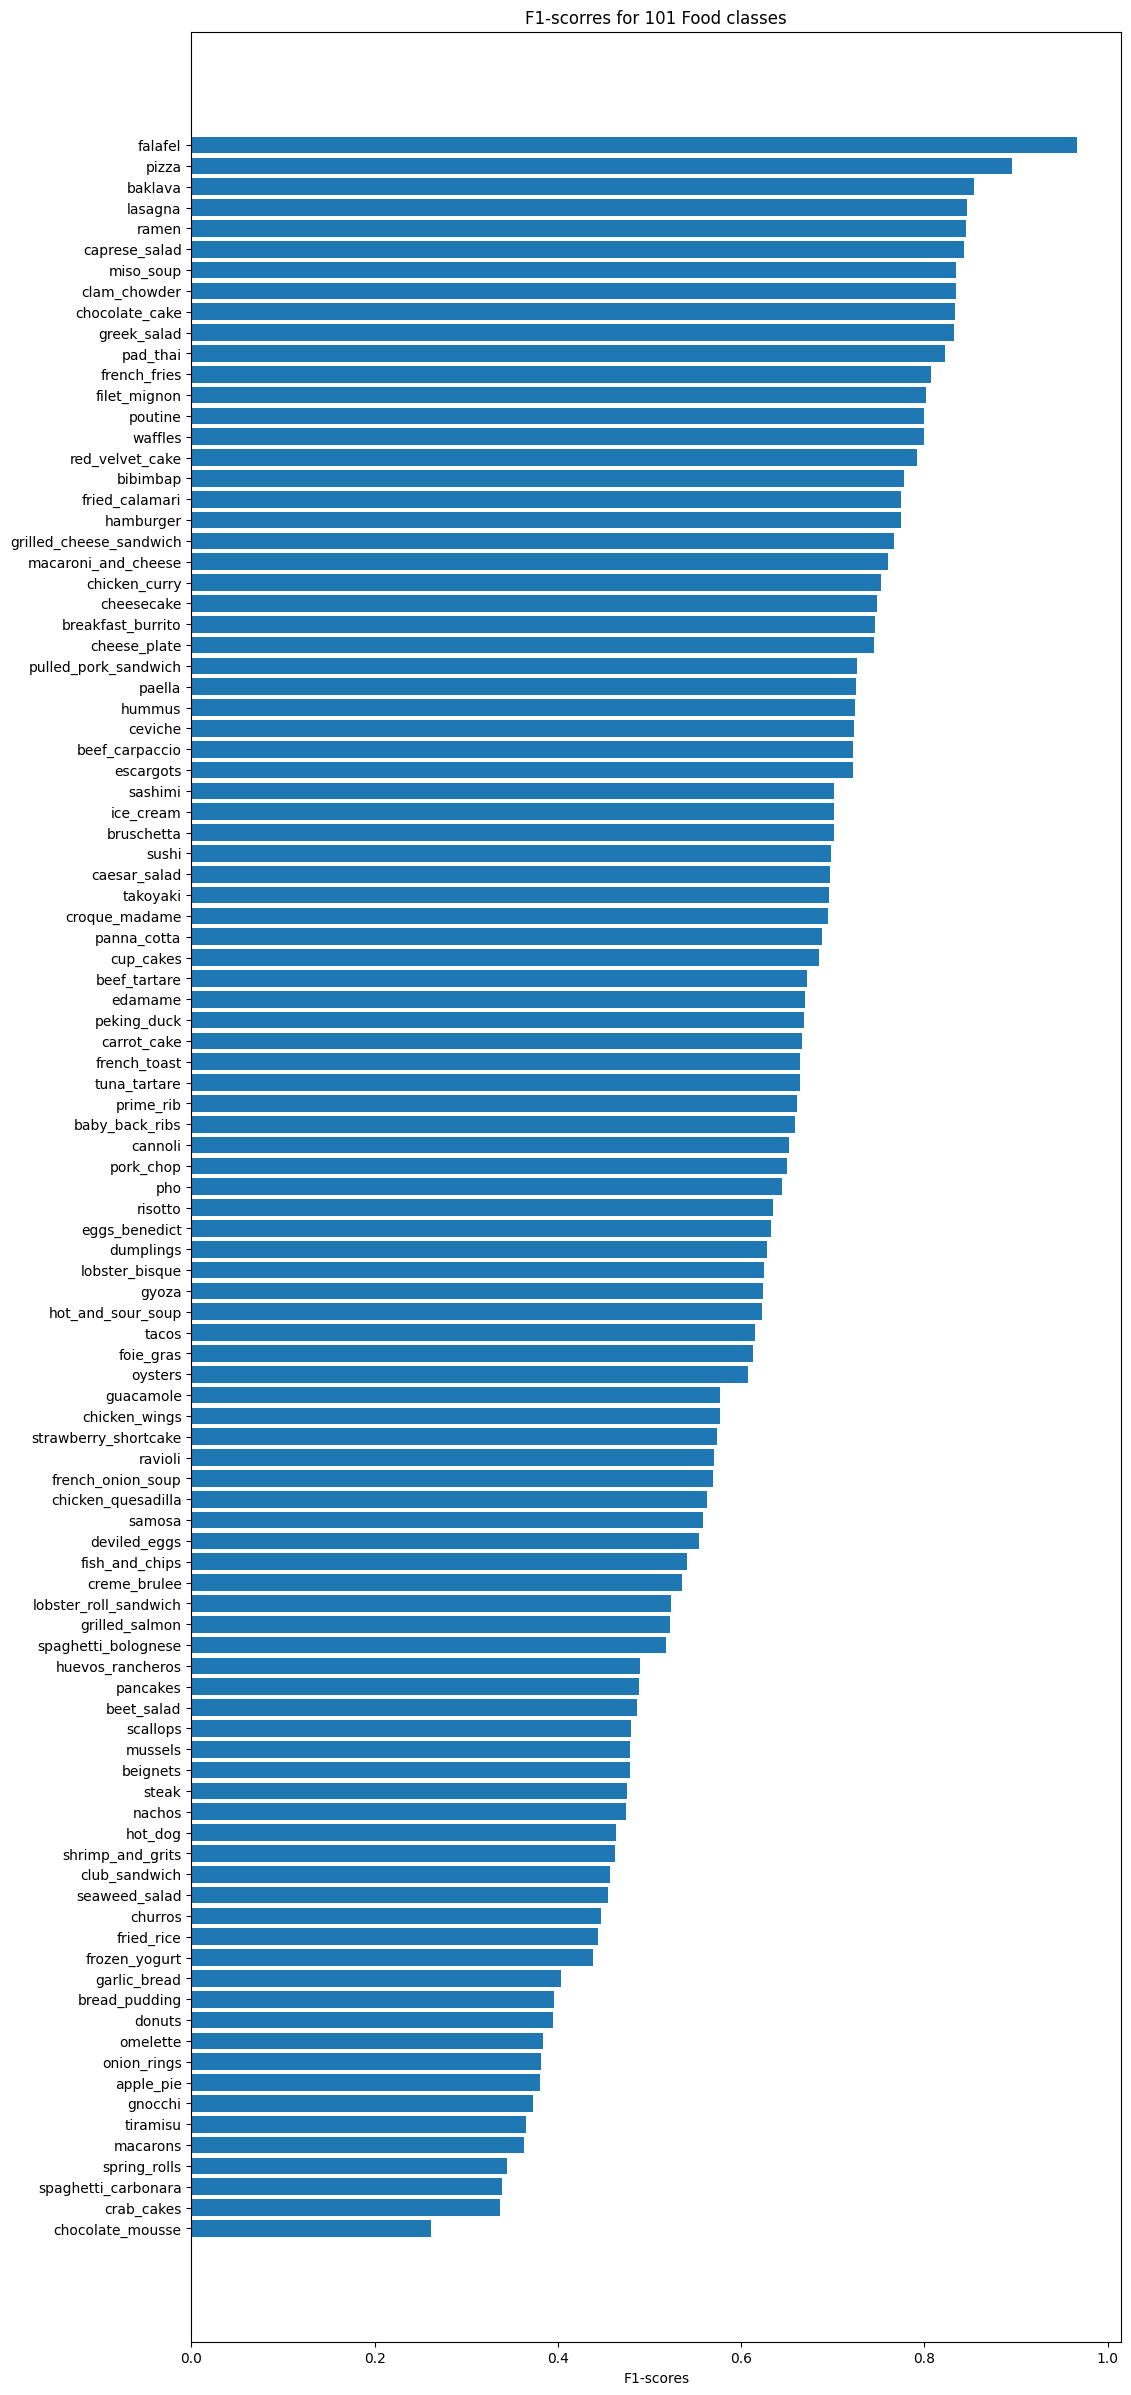

In [ ]:
fig, ax = plt.subplots(figsize=(12,30))
scores = ax.barh(range(len(f1_scores)), f1_scores["f1_scores"].values)
ax.set_yticks(range(len(f1_scores)))
ax.set_yticklabels(f1_scores["Class-names"]);
ax.set_xlabel("F1-scores")
ax.set_title("F1-scorres for 101 Food classes")
ax.invert_yaxis()

# Visulaizing predictions on custom images

**We will create a function to read and prepocess an image, that it will do the following**
1.   Read in a target image using tf.io.read_file().
2.   Turn the image into a tensor using tf.io.decode_image().
1.   Resize the im age tensor to be the same size as the images our model has trained on using tf.image.resize()
2.   Scale the imag to get all pixel values between 0 & 1





In [ ]:
# A function to load and preprocess image
def load_and_prep_image(filename, img_shape=224, scale=False):
  """
  Reads an image from filename, turns it into a tensor and reshapes it to (img_shape, img_shape, color_channels)

  Args:
  filename (str): path to the target image
  image_shape (int): height and width dimensions of the target image size
  scale (bool): whether to scale pixel values to range of 0 & 1 or not by default set to False

  Returns:
  Image tensor of shape (img_shape, img_shape, color_channels)
  """

  # 1. Read in the target image
  img = tf.io.read_file(filename=filename)

  # 2. turn the image into a tensor
  img = tf.image.decode_image(img, channels=3)

  # 3. Resize the image tensor
  img = tf.image.resize(img, size=[img_shape, img_shape])

  # 4. Rescale the image (get all values between 0 & 1) if scale=True
  if scale:
    return img/255.0
  else:
    return img



# Predicting and plotting 3 random images from the test_data

(224, 224, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
(224, 224, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
(224, 224, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


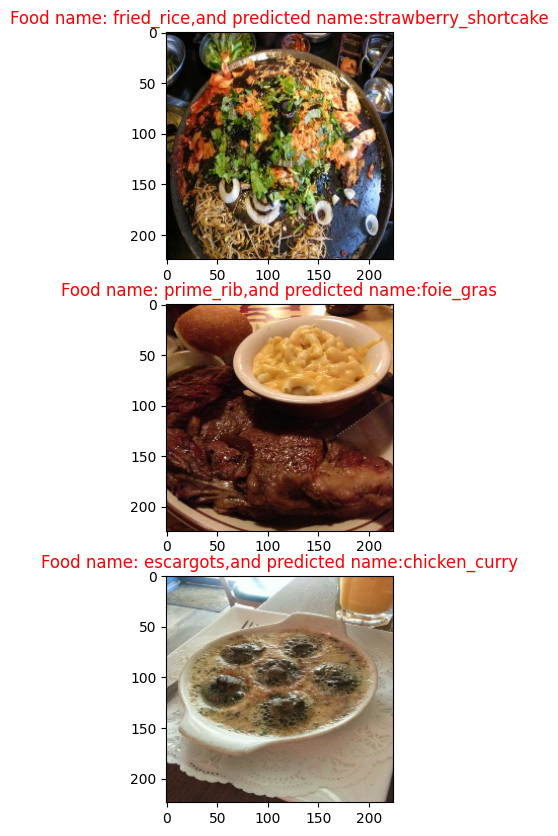

In [ ]:
plt.figure(figsize=(20,10))
for i in range(3):
  # Get a rndom class_name from test_dir
  class_name = random.choice(class_names)
  # Get a random file from the selected random class
  filename= random.choice(os.listdir(test_dir +"/" + class_name))
  filepath = test_dir +"/" + class_name +"/" + filename

  # Load and prepare the random image
  img = load_and_prep_image(filename=filepath, scale=False)
  print(img.shape)
  # Get prediction probability array
  pred_prob = model_1.predict(tf.expand_dims(img, axis=0))
  # Get the predicted class name
  pred_class = class_names[pred_prob.argmax()]
  plt.subplot(3,1,i+1)
  plt.imshow(img/255.0)

  if class_name == pred_class:
    title_color = "g"
  else:
    title_color = "r"
  plt.title(f"Food name: {class_name},and predicted name:{pred_class}", color=title_color)


# Finding the most wrong predictions
**To find the most wrong preedictions we cand do the following steps:**


1.   Get all of image file paths in the test dataset, we can use tf.list_files()
2.   Create a DataFrame of the image file paths, ground_truth labels, predicted classes, max prediction probabilities (prediction confidence), prediction class name, and ground truth class names.
3.   Use our DataFrame to find all the wrong predictions (where the ground truth dos not match our prediction)
4.   Sort the DataFrame based on the wring predictions in descending order.
5.   Visualize images with the highest prediction probabilities but have the wrong prediction.






In [ ]:
# 1. Get all of the image file paths in the test dataset
filepaths = []
pred_probs = []


for filepath in test_data.list_files("/content/101_food_classes_10_percent/test/*/*.jpg", shuffle=False):
  filepaths.append(filepath.numpy())  # Convert filepath to numpy format

filepaths

[b'/content/101_food_classes_10_percent/test/apple_pie/1011328.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/101251.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1034399.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/103801.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1038694.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1047447.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1068632.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/110043.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1106961.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1113017.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/116705.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1167170.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1174330.jpg',
 b'/content/101_food_classes_10_percent/test/apple_pie/1180600.jpg',
 b'/content/101_food_classes_10_percen

In [ ]:
print(len(filepaths),len(y_labels),len(pred_classes),len(preds_probs.max(axis=1)),len([class_names[i] for i in y_labels]), len([class_names[i] for i in pred_classes]))

25250 25250 0 25250 25250 0


In [ ]:
# 2. Creating a DataFrame of different parameters for each of our test images
pred_df = pd.DataFrame({"img_path": filepaths,
                        "y_true": y_labels,
                        "y-pred": pred_classes,
                        "pred_conf": preds_probs.max(axis=1), # Get the maximum preediction probability value
                        "y_true_classname":[class_names[i] for i in y_labels],
                        "y_pred_classmname": [class_names[i] for i in pred_classes],
                        })
pred_df

,img_path,y_true,y-pred,pred_conf,y_true_classname,y_pred_classmname
0,b'/content/101_food_classes_10_percent/test/ap...,0,0,0.411493,chocolate_mousse,chocolate_mousse
1,b'/content/101_food_classes_10_percent/test/ap...,0,0,0.947269,chocolate_mousse,chocolate_mousse
2,b'/content/101_food_classes_10_percent/test/ap...,0,0,0.511769,chocolate_mousse,chocolate_mousse
3,b'/content/101_food_classes_10_percent/test/ap...,0,38,0.255358,chocolate_mousse,hummus
4,b'/content/101_food_classes_10_percent/test/ap...,0,8,0.477815,chocolate_mousse,tiramisu
...,...,...,...,...,...,...
25245,b'/content/101_food_classes_10_percent/test/wa...,100,100,0.978127,ice_cream,ice_cream
25246,b'/content/101_food_classes_10_percent/test/wa...,100,100,0.752493,ice_cream,ice_cream
25247,b'/content/101_food_classes_10_percent/test/wa...,100,1,0.246353,ice_cream,foie_gras
25248,b'/content/101_food_classes_10_percent/test/wa...,100,94,0.402053,ice_cream,french_onion_soup


In [ ]:
# 3. Find the wrong predictions
pred_df["pred_correct"] = pred_df["y_true"] == pred_df["y-pred"]
pred_df.head()

,img_path,y_true,y-pred,pred_conf,y_true_classname,y_pred_classmname,pred_correct
0,b'/content/101_food_classes_10_percent/test/ap...,0,0,0.411493,chocolate_mousse,chocolate_mousse,True
1,b'/content/101_food_classes_10_percent/test/ap...,0,0,0.947269,chocolate_mousse,chocolate_mousse,True
2,b'/content/101_food_classes_10_percent/test/ap...,0,0,0.511769,chocolate_mousse,chocolate_mousse,True
3,b'/content/101_food_classes_10_percent/test/ap...,0,38,0.255358,chocolate_mousse,hummus,False
4,b'/content/101_food_classes_10_percent/test/ap...,0,8,0.477815,chocolate_mousse,tiramisu,False


In [ ]:
# 4. Sort the DataFrame based on the wring predictions in descending order.
top_100_wrong = pred_df[pred_df["pred_correct"]==False].sort_values("pred_conf", ascending=False)[:100]
top_100_wrong.head()

,img_path,y_true,y-pred,pred_conf,y_true_classname,y_pred_classmname,pred_correct
10847,b'/content/101_food_classes_10_percent/test/fr...,43,68,0.997315,edamame,miso_soup,False
23797,b'/content/101_food_classes_10_percent/test/su...,95,86,0.995329,baby_back_ribs,ramen,False
18001,b'/content/101_food_classes_10_percent/test/pa...,72,67,0.994554,pho,nachos,False
10013,b'/content/101_food_classes_10_percent/test/fr...,40,43,0.991682,bibimbap,edamame,False
11642,b'/content/101_food_classes_10_percent/test/ga...,46,10,0.991568,eggs_benedict,scallops,False


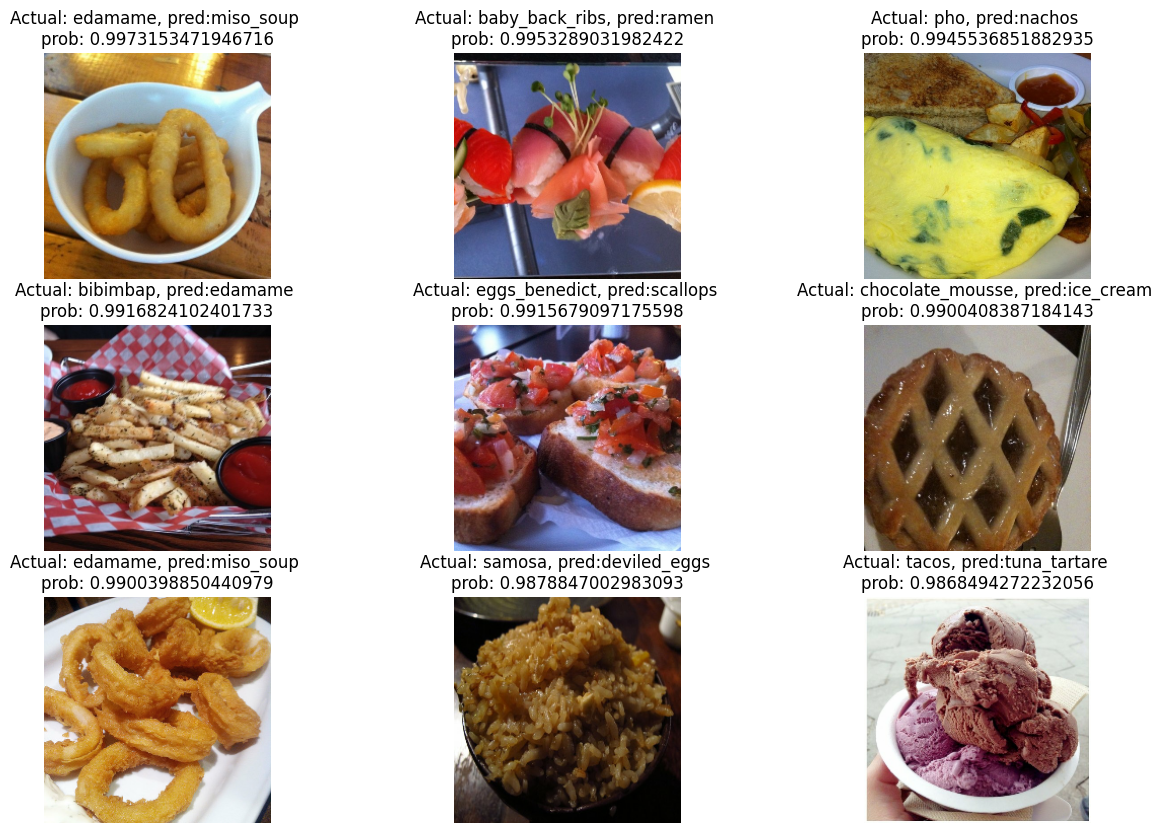

In [ ]:
#5.   Visualize images with the highest prediction probabilities but have the wrong prediction.
start_index = 0
images_to_view = 9
plt.figure(figsize=(15,10))
for i, row in enumerate(top_100_wrong[start_index:start_index+images_to_view].itertuples()):
  plt.subplot(3,3,i+1)
  _, img_path, _,_, pred_conf, y_true_classname, y_pred_classmname, _ = row
  img = load_and_prep_image(filename=img_path, scale=False)
  plt.imshow(img/255.0)
  plt.title(f"Actual: {y_true_classname}, pred:{y_pred_classmname} \nprob: {pred_conf}")
  plt.axis(False)


# Test out model on customimages

In [ ]:
# Import images
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/custom_food_images.zip

--2026-10-26 14:19:47--  https://storage.googleapis.com/ztm_tf_course/food_vision/custom_food_images.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.68.207, 142.251.10.207, 142.251.12.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.68.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13192985 (13M) [application/zip]
Saving to: ‘custom_food_images.zip’

custom_food_images. 100%[===================>]  12.58M  7.42MB/s    in 1.7s    

2026-10-26 14:19:49 (7.42 MB/s) - ‘custom_food_images.zip’ saved [13192985/13192985]



In [ ]:
# Unzipping custom image
unzip_data("/content/custom_food_images.zip")

In [ ]:
custom_images = ["/content/custom_food_images/" + img_path for img_path in os.listdir("/content/custom_food_images")]
custom_images

['/content/custom_food_images/chicken_wings.jpeg',
 '/content/custom_food_images/ramen.jpeg',
 '/content/custom_food_images/sushi.jpeg',
 '/content/custom_food_images/hamburger.jpeg',
 '/content/custom_food_images/pizza-dad.jpeg',
 '/content/custom_food_images/steak.jpeg']

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


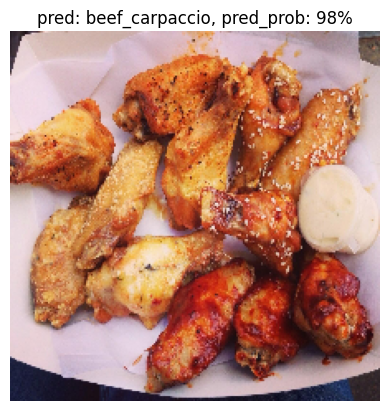

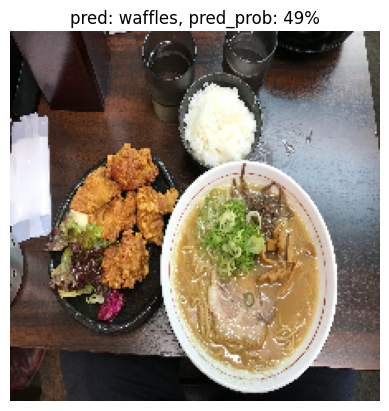

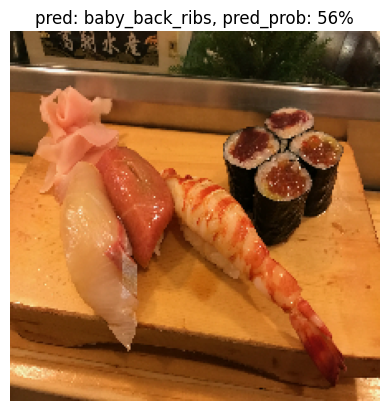

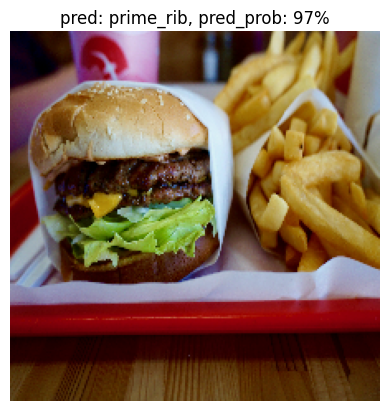

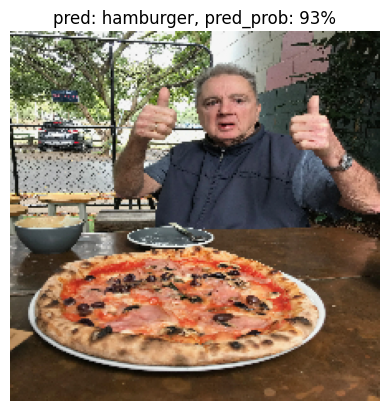

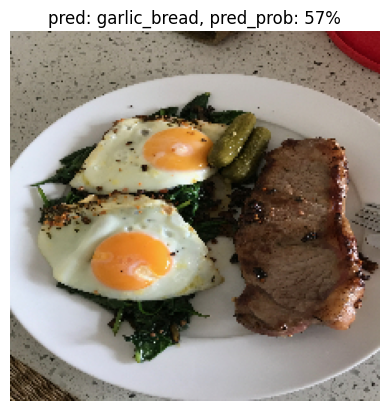

In [ ]:
# Make predictions and plot the custom images
for img in custom_images:
  img = load_and_prep_image(img, scale=False)
  pred_prob = model_1_loaded.predict(tf.expand_dims(img, 0))
  pred_class = class_names[pred_prob.argmax()]
  plt.figure()
  plt.imshow(img/255.0)
  plt.title(f"pred: {pred_class}, pred_prob: {pred_prob.max()*100 :.0f}%")
  plt.axis(False)